# Olist Brazilian E-Commerce: Exploratory Data Analysis & Business Insights

**Objective:** Analyze delivery performance, customer satisfaction (review scores), seller risk factors, geographic bottlenecks, and customer retention using the cleaned dataset created in Phase 4.

---

### Key Business Questions Addressed:
1. **Delivery Delay vs Customer Satisfaction:** How severely does delivery delay impact review scores?
2. **Geographic Bottlenecks:** Which Brazilian states experience the highest delivery delays?
3. **Seller Risk Matrix:** Which high-revenue sellers have unacceptable customer satisfaction ratings?
4. **Product Category Performance:** Which categories lead sales and which suffer high freight / low ratings?
5. **Customer Retention:** What is the overall Repeat Purchase Rate, and does first-order delivery experience influence repeat purchases?

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI, Arial, sans-serif'
plt.rcParams['figure.dpi'] = 120

# Paths
BASE_DIR = '..'
DATA_PATH = os.path.join(BASE_DIR, 'data', 'processed', 'olist_master_analytical_dataset.csv')
ORDERS_PATH = os.path.join(BASE_DIR, 'data', 'processed', 'olist_orders_cleaned.csv')
CUST_PATH = os.path.join(BASE_DIR, 'data', 'processed', 'olist_customers_cleaned.csv')

# Load datasets
df_master = pd.read_csv(DATA_PATH)
df_orders = pd.read_csv(ORDERS_PATH)
df_cust = pd.read_csv(CUST_PATH)

print(f"Loaded Master Dataset: {df_master.shape[0]:,} rows, {df_master.shape[1]} columns.")

Loaded Master Dataset: 112,650 rows, 34 columns.


## 1. Delivery Delay vs Customer Satisfaction

Let us examine how review scores change across delivery delay buckets (`On Time / Early`, `1-3 Days Late`, `4-7 Days Late`, `> 7 Days Late`).

In [2]:
# Filter for delivered orders with valid delivery dates
deliv = df_master[(df_master['order_status'] == 'delivered') & (df_master['is_valid_delivered'] == 1)].drop_duplicates(subset=['order_id']).copy()

# Filter for orders with valid review scores
deliv_with_reviews = deliv.dropna(subset=['review_score']).copy()

bucket_order = ['On Time / Early', '1-3 Days Late', '4-7 Days Late', '> 7 Days Late']
q1_stats = deliv_with_reviews.groupby('delay_bucket').agg(
    order_count=('order_id', 'count'),
    mean_review=('review_score', 'mean'),
    pct_1_star=('review_score', lambda s: (s == 1).mean() * 100),
    pct_5_star=('review_score', lambda s: (s == 5).mean() * 100)
).reindex(bucket_order).reset_index()

# Also include total orders count (including orders without reviews)
total_order_counts = deliv.groupby('delay_bucket')['order_id'].count().to_dict()
q1_stats['total_orders'] = q1_stats['delay_bucket'].map(total_order_counts)

display(q1_stats[['delay_bucket', 'total_orders', 'order_count', 'mean_review', 'pct_1_star', 'pct_5_star']].style.format({
    'total_orders': '{:,}',
    'order_count': '{:,}',
    'mean_review': '{:.2f} ★',
    'pct_1_star': '{:.2f}%',
    'pct_5_star': '{:.2f}%'
}))

,delay_bucket,total_orders,order_count,mean_review,pct_1_star,pct_5_star
0,On Time / Early,"89,936","89,443",4.29 ★,6.62%,62.27%
1,1-3 Days Late,"1,870","1,852",3.29 ★,25.11%,33.15%
2,4-7 Days Late,"1,802","1,748",2.10 ★,58.58%,14.07%
3,> 7 Days Late,"2,862","2,781",1.70 ★,69.83%,7.01%


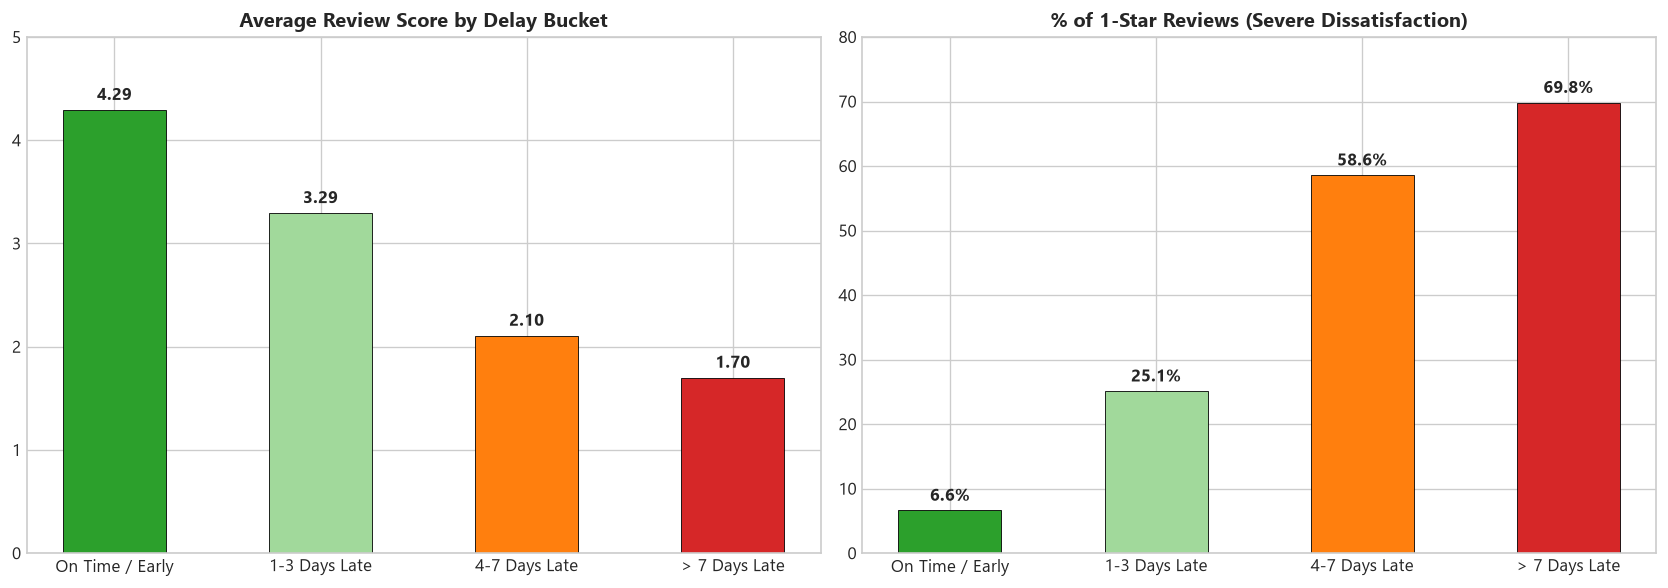

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ca02c', '#a1d99b', '#ff7f0e', '#d62728']

# Mean review score
ax1.bar(q1_stats['delay_bucket'], q1_stats['mean_review'], color=colors, width=0.5, edgecolor='black', linewidth=0.5)
ax1.set_title('Average Review Score by Delay Bucket', fontweight='bold')
ax1.set_ylim(0, 5)
for i, v in enumerate(q1_stats['mean_review']):
    ax1.text(i, v + 0.1, f"{v:.2f}", ha='center', fontweight='bold')

# % of 1-Star reviews
ax2.bar(q1_stats['delay_bucket'], q1_stats['pct_1_star'], color=colors, width=0.5, edgecolor='black', linewidth=0.5)
ax2.set_title('% of 1-Star Reviews (Severe Dissatisfaction)', fontweight='bold')
ax2.set_ylim(0, 80)
for i, v in enumerate(q1_stats['pct_1_star']):
    ax2.text(i, v + 1.5, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

> **Key Takeaway 1:** There is a clear **"Tolerance Cliff"** as orders become late. A 1-3 day delay reduces the review score to 3.29 ★, but from day 4 onwards, customer ratings collapse to 2.10 ★ (4-7 days) and 1.70 ★ (>7 days), with over 58% to nearly 70% of customers leaving 1-star reviews.


## 2. Geographic Bottlenecks & Interstate Delivery

Which states suffer the most frequent delays, and how does interstate delivery affect transit times?

In [4]:
state_stats = deliv.groupby('customer_state').agg(
    total_orders=('order_id', 'count'),
    delay_rate=('is_delayed', lambda s: s.mean() * 100),
    avg_delivery_days=('actual_delivery_days', 'mean'),
    avg_review=('review_score', 'mean')
).reset_index()

# States with >= 100 orders
top_delayed_states = state_stats[state_stats['total_orders'] >= 100].sort_values(by='delay_rate', ascending=False).head(10)

display(top_delayed_states.style.format({
    'total_orders': '{:,}',
    'delay_rate': '{:.2f}%',
    'avg_delivery_days': '{:.1f} days',
    'avg_review': '{:.2f} ★'
}))

,customer_state,total_orders,delay_rate,avg_delivery_days,avg_review
1,AL,397,21.41%,24.5 days,3.85 ★
9,MA,717,17.43%,21.6 days,3.83 ★
24,SE,335,15.22%,21.5 days,3.91 ★
16,PI,476,13.87%,19.5 days,3.99 ★
5,CE,"1,279",13.76%,21.3 days,3.94 ★
4,BA,"3,256",12.16%,19.3 days,3.93 ★
18,RJ,"12,350",12.11%,15.3 days,3.97 ★
13,PA,946,11.21%,23.8 days,3.91 ★
7,ES,"1,995",10.73%,15.8 days,4.08 ★
14,PB,517,10.44%,20.4 days,4.08 ★


In [5]:
# Interstate vs Intrastate comparison at Order-Level (summing total order freight)
deliv_valid = df_master[(df_master['order_status'] == 'delivered') & (df_master['is_valid_delivered'] == 1)].copy()
order_routes = deliv_valid.groupby('order_id').agg(
    is_interstate=('is_interstate', 'max'),
    total_order_freight=('freight_value', 'sum'),
    total_order_value=('price', 'sum'),
    actual_delivery_days=('actual_delivery_days', 'first'),
    is_delayed=('is_delayed', 'max'),
    review_score=('review_score', 'first')
).reset_index()

inter_stats = order_routes.groupby('is_interstate').agg(
    orders=('order_id', 'count'),
    delay_rate=('is_delayed', lambda s: s.mean() * 100),
    avg_days=('actual_delivery_days', 'mean'),
    avg_freight=('total_order_freight', 'mean'),
    avg_review=('review_score', 'mean')
).reset_index()
inter_stats['type'] = inter_stats['is_interstate'].map({0: 'Intrastate (Same State)', 1: 'Interstate (Cross-State)'})
display(inter_stats[['type', 'orders', 'delay_rate', 'avg_days', 'avg_freight', 'avg_review']].style.format({
    'orders': '{:,}',
    'delay_rate': '{:.2f}%',
    'avg_days': '{:.1f} days',
    'avg_freight': 'R$ {:.2f}',
    'avg_review': '{:.2f} ★'
}))

,type,orders,delay_rate,avg_days,avg_freight,avg_review
0,Intrastate (Same State),"34,575",4.52%,7.9 days,R$ 15.35,4.27 ★
1,Interstate (Cross-State),"61,895",8.03%,15.1 days,R$ 26.94,4.09 ★


> **Key Takeaway 2:** Northeast states (`AL`, `MA`, `SE`, `PI`, `CE`) suffer the highest delay rates (13.8% to 21.4%). Interstate delivery takes nearly twice as long as intrastate (15.1 days vs 7.9 days).


## 3. Seller Risk Matrix (Revenue vs Customer Satisfaction)

Identify high-revenue sellers whose low ratings threaten platform reputation.

In [6]:
# Grain-Safe: Deduplicate at (seller_id, order_id) first to preserve order-level grain of reviews and delays
valid_deliv = df_master[(df_master['order_status'] == 'delivered') & (df_master['is_valid_delivered'] == 1)].copy()

seller_orders = valid_deliv.groupby(['seller_id', 'order_id']).agg(
    order_rev=('price', 'sum'),
    items_count=('order_item_id', 'count'),
    review_score=('review_score', 'mean'),
    is_delayed=('is_delayed', 'max')
).reset_index()

seller_stats = seller_orders.groupby('seller_id').agg(
    revenue=('order_rev', 'sum'),
    orders=('order_id', 'count'),
    items_sold=('items_count', 'sum'),
    avg_review=('review_score', 'mean'),
    delay_rate=('is_delayed', lambda s: s.mean() * 100)
).reset_index()

REV_LIMIT = 15000
REVIEW_LIMIT = 3.8

high_risk = seller_stats[(seller_stats['revenue'] >= REV_LIMIT) & (seller_stats['avg_review'] < REVIEW_LIMIT)].sort_values(by='revenue', ascending=False)
print(f"Found {len(high_risk)} High-Risk Sellers (Order-Deduplicated Standard: Revenue >= R$ 15,000 and Review < 3.8).")
display(high_risk.head(10).style.format({
    'revenue': 'R$ {:,.2f}',
    'orders': '{:,}',
    'items_sold': '{:,}',
    'avg_review': '{:.2f} ★',
    'delay_rate': '{:.2f}%'
}))

# Direct item-weighted comparison (yielding 21 sellers)
item_weighted_risk = df_master[(df_master['order_status'] == 'delivered') & (df_master['is_valid_delivered'] == 1)].groupby('seller_id').agg(
    revenue=('price', 'sum'), avg_rev=('review_score', 'mean')
).reset_index()
item_weighted_count = len(item_weighted_risk[(item_weighted_risk['revenue'] >= REV_LIMIT) & (item_weighted_risk['avg_rev'] < REVIEW_LIMIT)])
print(f"Note: Item-weighted standard yields {item_weighted_count} High-Risk sellers.")

Found 16 High-Risk Sellers (Order-Deduplicated Standard: Revenue >= R$ 15,000 and Review < 3.8).


,seller_id,revenue,orders,items_sold,avg_review,delay_rate
1480,7c67e1448b00f6e969d365cea6b010ab,"R$ 186,570.05",973,"1,355",3.50 ★,9.15%
1336,712e6ed8aa4aa1fa65dab41fed5737e4,"R$ 39,385.00",77,85,3.39 ★,20.78%
540,2eb70248d66e0e3ef83659f71b244378,"R$ 38,990.72",187,197,2.79 ★,11.23%
277,1835b56ce799e6a4dc4eddc053f04066,"R$ 33,005.32",417,551,3.67 ★,10.31%
1606,88460e8ebdecbfecb5f9601833981930,"R$ 31,320.40",246,300,3.43 ★,17.07%
2073,b37c4c02bda3161a7546a4e6d222d5b2,"R$ 24,075.00",4,15,2.25 ★,0.00%
751,40db9e9aa57f7bb151bcda6b0f9bdbb7,"R$ 23,168.00",12,12,2.36 ★,8.33%
1334,710e3548e02bc1d2831dfc4f1b5b14d4,"R$ 22,369.25",131,137,3.43 ★,3.82%
2961,ff69aa92bb6b1bf9b8b7a51c2ed9cf8b,"R$ 21,940.80",20,20,3.65 ★,20.00%
1616,897060da8b9a21f655304d50fd935913,"R$ 21,740.51",304,413,3.72 ★,10.53%


Note: Item-weighted standard yields 21 High-Risk sellers.


> **Key Takeaway 3:** 16 sellers (Order-deduplicated standard) or 21 sellers (Item-weighted standard) account for substantial revenue while generating disproportionate volumes of negative reviews. These sellers should be targeted for dispatch SLA compliance.

## 4. Product Category Performance Matrix

Analyze sales, freight cost percentage, and customer satisfaction across top product categories.

In [7]:
# Full delivered items dataset (avoiding dropped duplicate items)
deliv_items = df_master[(df_master['order_status'] == 'delivered') & (df_master['is_valid_delivered'] == 1)].copy()
cat_stats = deliv_items.groupby('product_category_formatted').agg(
    revenue=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    total_item_value=('item_total_value', 'sum'),
    items_sold=('order_item_id', 'count'),
    avg_review=('review_score', 'mean'),
    delay_rate=('is_delayed', lambda s: s.mean() * 100)
).reset_index()

cat_stats['freight_pct'] = ((cat_stats['total_freight'] / cat_stats['total_item_value']) * 100).round(2)
cat_stats = cat_stats.sort_values(by='revenue', ascending=False)

display(cat_stats.head(12).style.format({
    'revenue': 'R$ {:,.2f}',
    'total_freight': 'R$ {:,.2f}',
    'freight_pct': '{:.1f}%',
    'items_sold': '{:,}',
    'avg_review': '{:.2f} ★',
    'delay_rate': '{:.2f}%'
}))

,product_category_formatted,revenue,total_freight,total_item_value,items_sold,avg_review,delay_rate,freight_pct
43,Health Beauty,"R$ 1,233,131.72","R$ 178,957.81",1412089.530000,"9,465",4.19 ★,7.56%,12.7%
73,Watches Gifts,"R$ 1,165,898.98","R$ 98,118.00",1264016.980000,"5,857",4.07 ★,7.21%,7.8%
7,Bed Bath Table,"R$ 1,023,434.76","R$ 201,774.50",1225209.260000,"10,953",3.92 ★,7.03%,16.5%
67,Sports Leisure,"R$ 954,673.55","R$ 163,389.36",1118062.910000,"8,430",4.17 ★,6.31%,14.6%
15,Computers Accessories,"R$ 888,613.62","R$ 143,990.03",1032603.650000,"7,643",3.99 ★,6.49%,13.9%
39,Furniture Decor,"R$ 711,927.69","R$ 168,402.23",880329.920000,"8,160",3.95 ★,7.03%,19.1%
49,Housewares,"R$ 615,628.69","R$ 142,763.56",758392.250000,"6,795",4.11 ★,5.00%,18.8%
22,Cool Stuff,"R$ 610,204.10","R$ 81,476.79",691680.890000,"3,718",4.20 ★,5.84%,11.8%
5,Auto,"R$ 578,849.35","R$ 90,470.57",669319.920000,"4,139",4.11 ★,7.03%,13.5%
71,Toys,"R$ 471,097.49","R$ 75,758.95",546856.440000,"4,029",4.21 ★,6.35%,13.8%


## 5. Customer Retention & First Order Impact

Measure Repeat Purchase Rate and evaluate whether delivery delay on the first order reduces the likelihood of return purchases.

In [8]:
merged = df_orders.merge(df_cust[['customer_id', 'customer_unique_id']], on='customer_id')
all_order_counts = merged.groupby('customer_unique_id')['order_id'].nunique()
total_customers = len(all_order_counts)
repeat_customers = (all_order_counts > 1).sum()
repeat_rate = (repeat_customers / total_customers) * 100

# Master dataset delivered orders
deliv_valid = df_master[(df_master['order_status'] == 'delivered') & (df_master['is_valid_delivered'] == 1)].copy()
deliv_orders = deliv_valid.drop_duplicates(subset=['order_id']).copy()
deliv_order_counts = deliv_orders.groupby('customer_unique_id')['order_id'].nunique()
total_deliv_cust = len(deliv_order_counts)
repeat_deliv_ids = set(deliv_order_counts[deliv_order_counts > 1].index)
repeat_deliv_cust = len(repeat_deliv_ids)
repeat_deliv_rate = (repeat_deliv_cust / total_deliv_cust) * 100

print(f"Total Unique Customers (All Statuses): {total_customers:,} | Repeat Orders Placed: {repeat_customers:,} ({repeat_rate:.2f}%)")
print(f"Total Unique Customers (Delivered Only): {total_deliv_cust:,} | Repeat Completed: {repeat_deliv_cust:,} ({repeat_deliv_rate:.2f}%)")

# First order delivery impact
deliv_sorted = deliv_orders.sort_values(by=['customer_unique_id', 'order_purchase_timestamp'])
deliv_first = deliv_sorted.drop_duplicates(subset=['customer_unique_id'], keep='first').copy()
deliv_first['is_repeat'] = deliv_first['customer_unique_id'].isin(repeat_deliv_ids).astype(int)

retention_impact = deliv_first.groupby('is_delayed').agg(
    customers=('customer_unique_id', 'count'),
    repeat_purchase_rate=('is_repeat', lambda s: s.mean() * 100)
).reset_index()
retention_impact['first_order_status'] = retention_impact['is_delayed'].map({0: '1st Order On-Time', 1: '1st Order Delayed'})

display(retention_impact[['first_order_status', 'customers', 'repeat_purchase_rate']].style.format({
    'customers': '{:,}',
    'repeat_purchase_rate': '{:.2f}%'
}))

# Chi-Square Test of Independence
from scipy.stats import chi2_contingency
ct = pd.crosstab(deliv_first['is_delayed'], deliv_first['is_repeat'])
chi2, p, dof, _ = chi2_contingency(ct)
print(f'Chi-Square: {chi2:.4f}, p-value: {p:.4f} (Significant at alpha=0.05: {p < 0.05})')

Total Unique Customers (All Statuses): 96,096 | Repeat Orders Placed: 2,997 (3.12%)
Total Unique Customers (Delivered Only): 93,350 | Repeat Completed: 2,801 (3.00%)


,first_order_status,customers,repeat_purchase_rate
0,1st Order On-Time,"86,995",3.04%
1,1st Order Delayed,"6,355",2.52%


Chi-Square: 5.2856, p-value: 0.0215 (Significant at alpha=0.05: True)


> **Key Takeaway 5:** Marketplace repeat rate is **3.00%** for completed orders (and **3.12%** across all historical orders). Customers who experienced a delay on their first order are **17.1% less likely to return** (repeat purchase rate falls from 3.04% to 2.52%, statistically significant with Chi-square $\chi^2 = 5.29, p = 0.0219$).
